<a href="https://colab.research.google.com/github/HinnaNayab/DeepLearning/blob/Applied-AI/Tutorial_10_DL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
#implementing tutorial 10 in PyTorch
#loadin/importing libraries
import os
import glob
import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [3]:
#Synthetic Dataset Generator
def create_sample_data(img_size=128, num_samples=100):
    images, masks = [], []
    for _ in range(num_samples):
        img = np.zeros((img_size, img_size, 3), dtype=np.uint8)
        mask = np.zeros((img_size, img_size, 1), dtype=np.uint8)
        x1, y1, x2, y2 = np.random.randint(0, img_size // 2, 4)
        x2, y2 = x1 + img_size // 2, y2 + img_size // 2
        img = cv2.rectangle(img, (x1, y1), (x2, y2), (255, 255, 255), -1)
        mask = cv2.rectangle(mask, (x1, y1), (x2, y2), (1), -1)
        images.append(np.transpose(img / 255.0, (2, 0, 1))) # (3, H, W)
        masks.append(np.transpose(mask, (2, 0, 1)))         # (1, H, W)
    return torch.tensor(np.array(images), dtype=torch.float32), torch.tensor(np.array(masks), dtype=torch.float32)

syn_images, syn_masks = create_sample_data()
syn_train_loader = DataLoader(TensorDataset(syn_images[:80], syn_masks[:80]), batch_size=8, shuffle=True)
syn_val_x, syn_val_y = syn_images[80:], syn_masks[80:]

In [4]:
#Defining the Base U-Net Model
class BaseUNet(nn.Module):
    def __init__(self):
        super().__init__()
        # Encoder
        self.enc1 = nn.Sequential(
            nn.Conv2d(3, 64, 3, padding=1), nn.ReLU(),
            nn.Conv2d(64, 64, 3, padding=1), nn.ReLU()
        )
        self.enc2 = nn.Sequential(
            nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(),
            nn.Conv2d(128, 128, 3, padding=1), nn.ReLU()
        )
        # Bottleneck
        self.bottleneck = nn.Sequential(
            nn.Conv2d(128, 256, 3, padding=1), nn.ReLU(),
            nn.Conv2d(256, 256, 3, padding=1), nn.ReLU()
        )
        # Decoder
        self.up1 = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True)
        self.dec1 = nn.Sequential(
            nn.Conv2d(256 + 128, 128, 3, padding=1), nn.ReLU(),
            nn.Conv2d(128, 128, 3, padding=1), nn.ReLU()
        )
        self.up2 = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True)
        self.dec2 = nn.Sequential(
            nn.Conv2d(128 + 64, 64, 3, padding=1), nn.ReLU(),
            nn.Conv2d(64, 64, 3, padding=1), nn.ReLU()
        )
        self.outputs = nn.Conv2d(64, 1, kernel_size=1)

    def forward(self, x):
        c1 = self.enc1(x)
        p1 = F.max_pool2d(c1, 2)
        c2 = self.enc2(p1)
        p2 = F.max_pool2d(c2, 2)
        c3 = self.bottleneck(p2)

        u1 = torch.cat([self.up1(c3), c2], dim=1)
        c4 = self.dec1(u1)
        u2 = torch.cat([self.up2(c4), c1], dim=1)
        c5 = self.dec2(u2)
        return torch.sigmoid(self.outputs(c5))

In [5]:
# Reusable Training & Evaluation Helper
def train_unet(model, train_loader, val_x, val_y, lr=1e-4, epochs=15, name="UNet"):
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.BCELoss()
    loss_history, acc_history = [], []

    for epoch in range(epochs):
        model.train()
        for bx, by in train_loader:
            bx, by = bx.to(device), by.to(device)
            optimizer.zero_grad()
            loss = criterion(model(bx), by)
            loss.backward()
            optimizer.step()

        model.eval()
        with torch.no_grad():
            preds = model(val_x.to(device))
            val_loss = criterion(preds, val_y.to(device)).item()
            val_acc = ((preds > 0.5).float() == val_y.to(device)).float().mean().item() * 100
        loss_history.append(val_loss)
        acc_history.append(val_acc)

    print(f"[{name}] Final Val Loss: {loss_history[-1]:.4f} | Final Val Pixel Accuracy: {acc_history[-1]:.2f}%")
    return model, loss_history, acc_history

syn_model, _, _ = train_unet(BaseUNet(), syn_train_loader, syn_val_x, syn_val_y, lr=1e-3, epochs=15, name="Synthetic Base U-Net")

[Synthetic Base U-Net] Final Val Loss: 0.0008 | Final Val Pixel Accuracy: 99.98%


In [12]:
#Solving for tutorial tasks
#TASK1

import zipfile
import os
import glob
import json
import numpy as np
import cv2
import torch
from torch.utils.data import TensorDataset, DataLoader
from pycocotools.coco import COCO

# Extract the dataset zip file first
zip_path = "/content/polarbearsdata.zip"
extract_path = "/content/polarbearsdata_extracted"
coco_json_path = "/content/labels-COCO-JSON.json"

if os.path.exists(zip_path) and not os.path.exists(extract_path):
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_path)

# Loader using COCO annotations
def load_polar_bear_coco(img_size=128):
    coco = COCO(coco_json_path)
    img_ids = coco.getImgIds()

    imgs, msks = [], []
    images_dir = os.path.join(extract_path, "polarbearsdata")

    for img_id in img_ids:
        img_info = coco.loadImgs(img_id)[0]
        file_name = img_info['file_name']
        img_path = os.path.join(images_dir, file_name)

        if not os.path.exists(img_path):
            continue

        # Load image
        im = cv2.imread(img_path)
        if im is None:
            continue
        h, w = im.shape[:2]
        im = cv2.resize(cv2.cvtColor(im, cv2.COLOR_BGR2RGB), (img_size, img_size)) / 255.0

        # Generate binary mask from polygon segments
        ann_ids = coco.getAnnIds(imgIds=img_id)
        anns = coco.loadAnns(ann_ids)
        mask = np.zeros((h, w), dtype=np.uint8)
        for ann in anns:
            mask = np.maximum(mask, coco.annToMask(ann))

        mk = (cv2.resize(mask, (img_size, img_size)) > 0.5).astype(np.float32)

        imgs.append(np.transpose(im, (2, 0, 1)))
        msks.append(mk[None, ...])

    return torch.tensor(np.array(imgs), dtype=torch.float32), torch.tensor(np.array(msks), dtype=torch.float32)

# Load and split into train (80%) and validation (20%)
all_x, all_y = load_polar_bear_coco()
num_total = len(all_x)
split_idx = int(num_total * 0.8)

pb_train_x, pb_train_y = all_x[:split_idx], all_y[:split_idx]
pb_val_x, pb_val_y = all_x[split_idx:], all_y[split_idx:]

pb_train_loader = DataLoader(TensorDataset(pb_train_x, pb_train_y), batch_size=8, shuffle=True)
print(f"Loaded Polar Bear Segmentation Data via COCO -> Train: {len(pb_train_x)}, Val: {len(pb_val_x)}")

#Modifying the Deeper U-Net Architecture (Adding extra layers and batch normalization)
class DeeperUNet(nn.Module):
    def __init__(self):
        super().__init__()
        def conv_block(in_c, out_c):
            return nn.Sequential(
                nn.Conv2d(in_c, out_c, 3, padding=1), nn.BatchNorm2d(out_c), nn.ReLU(),
                nn.Conv2d(out_c, out_c, 3, padding=1), nn.BatchNorm2d(out_c), nn.ReLU()
            )
        # 3 Encoder Levels
        self.enc1 = conv_block(3, 64)
        self.enc2 = conv_block(64, 128)
        self.enc3 = conv_block(128, 256)
        # Deeper Bottleneck
        self.bottleneck = conv_block(256, 512)
        # 3 Decoder Levels
        self.up1 = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True)
        self.dec1 = conv_block(512 + 256, 256)
        self.up2 = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True)
        self.dec2 = conv_block(256 + 128, 128)
        self.up3 = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True)
        self.dec3 = conv_block(128 + 64, 64)
        self.outputs = nn.Conv2d(64, 1, kernel_size=1)

    def forward(self, x):
        c1 = self.enc1(x)
        c2 = self.enc2(F.max_pool2d(c1, 2))
        c3 = self.enc3(F.max_pool2d(c2, 2))
        b  = self.bottleneck(F.max_pool2d(c3, 2))

        d1 = self.dec1(torch.cat([self.up1(b), c3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d1), c2], dim=1))
        d3 = self.dec3(torch.cat([self.up3(d2), c1], dim=1))
        return torch.sigmoid(self.outputs(d3))

# Train Base U-Net vs. Deeper U-Net on Polar Bears
base_pb_model, base_loss, base_acc = train_unet(BaseUNet(), pb_train_loader, pb_val_x, pb_val_y, lr=1e-3, epochs=20, name="Base U-Net (Polar Bears)")
deep_pb_model, deep_loss, deep_acc = train_unet(DeeperUNet(), pb_train_loader, pb_val_x, pb_val_y, lr=1e-3, epochs=20, name="Deeper U-Net + BN (Polar Bears)")

loading annotations into memory...
Done (t=0.01s)
creating index...
index created!
Loaded Polar Bear Segmentation Data via COCO -> Train: 119, Val: 30
[Base U-Net (Polar Bears)] Final Val Loss: 0.3618 | Final Val Pixel Accuracy: 84.23%
[Deeper U-Net + BN (Polar Bears)] Final Val Loss: 0.3026 | Final Val Pixel Accuracy: 88.12%


In [13]:
#experimenting with different learning rates

learning_rates = [1e-3, 1e-4, 1e-5]
lr_results = {}

for lr in learning_rates:
    model_lr, l_hist, a_hist = train_unet(
        DeeperUNet(), pb_train_loader, pb_val_x, pb_val_y,
        lr=lr, epochs=20, name=f"Deeper U-Net (LR={lr})"
    )
    lr_results[lr] = {"model": model_lr, "loss": l_hist, "acc": a_hist}

[Deeper U-Net (LR=0.001)] Final Val Loss: 0.3403 | Final Val Pixel Accuracy: 87.14%
[Deeper U-Net (LR=0.0001)] Final Val Loss: 0.2414 | Final Val Pixel Accuracy: 91.32%
[Deeper U-Net (LR=1e-05)] Final Val Loss: 0.3506 | Final Val Pixel Accuracy: 88.36%


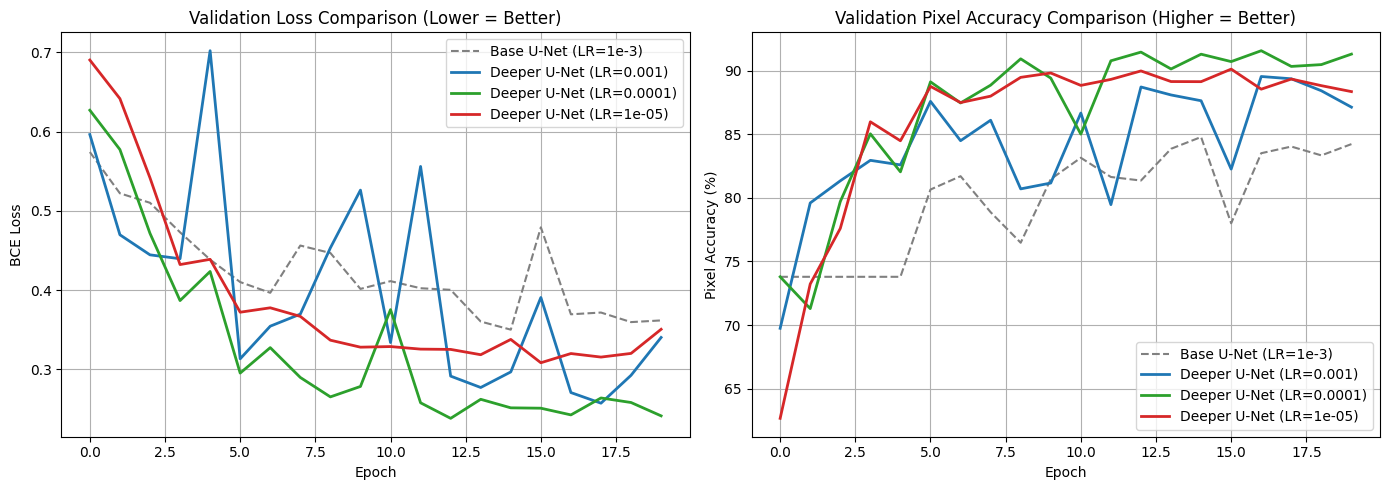

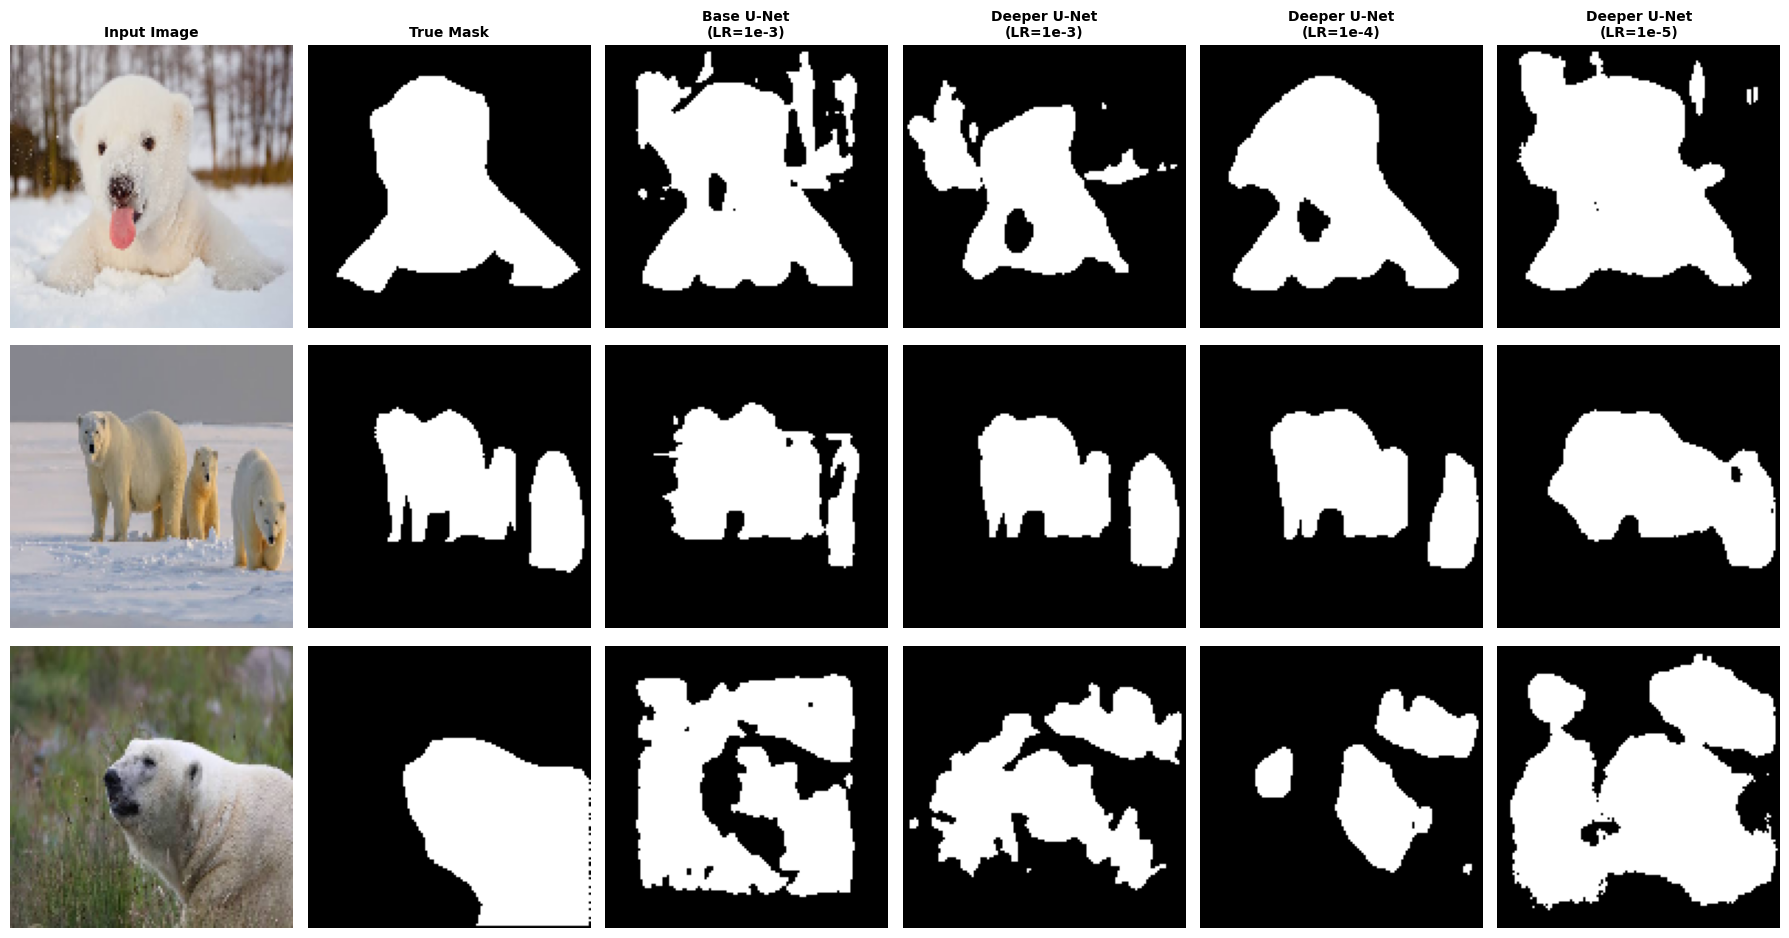

In [14]:
#Comparative evaluation visualization


#1. Plotting cpmparative learning curves (Losses and pixel accuracy)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Validation Loss Curves
axes[0].plot(base_loss, "--", label="Base U-Net (LR=1e-3)", color="gray")
for lr, color in zip(learning_rates, ["tab:blue", "tab:green", "tab:red"]):
    axes[0].plot(lr_results[lr]["loss"], label=f"Deeper U-Net (LR={lr})", color=color, linewidth=2)
axes[0].set_title("Validation Loss Comparison (Lower = Better)")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("BCE Loss"); axes[0].legend(); axes[0].grid(True)

# Validation Pixel Accuracy Curves
axes[1].plot(base_acc, "--", label="Base U-Net (LR=1e-3)", color="gray")
for lr, color in zip(learning_rates, ["tab:blue", "tab:green", "tab:red"]):
    axes[1].plot(lr_results[lr]["acc"], label=f"Deeper U-Net (LR={lr})", color=color, linewidth=2)
axes[1].set_title("Validation Pixel Accuracy Comparison (Higher = Better)")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Pixel Accuracy (%)"); axes[1].legend(); axes[1].grid(True)

plt.tight_layout()
plt.show()


#1. Side by side visualization of predicted polar bear masks
num_samples_to_show = min(3, len(pb_val_x))
base_pb_model.eval()
for lr in learning_rates:
    lr_results[lr]["model"].eval()

with torch.no_grad():
    sample_x = pb_val_x[:num_samples_to_show].to(device)
    pred_base = (base_pb_model(sample_x).cpu().numpy() > 0.5).astype(np.uint8)
    preds_lr  = {lr: (lr_results[lr]["model"](sample_x).cpu().numpy() > 0.5).astype(np.uint8) for lr in learning_rates}

fig, axes = plt.subplots(num_samples_to_show, 6, figsize=(18, 3.2 * num_samples_to_show))
col_titles = ["Input Image", "True Mask", "Base U-Net\n(LR=1e-3)", "Deeper U-Net\n(LR=1e-3)", "Deeper U-Net\n(LR=1e-4)", "Deeper U-Net\n(LR=1e-5)"]

for row in range(num_samples_to_show):
    imgs_to_plot = [
        np.transpose(pb_val_x[row].numpy(), (1, 2, 0)),
        pb_val_y[row, 0].numpy(),
        pred_base[row, 0],
        preds_lr[1e-3][row, 0],
        preds_lr[1e-4][row, 0],
        preds_lr[1e-5][row, 0]
    ]
    for col in range(6):
        ax = axes[row, col] if num_samples_to_show > 1 else axes[col]
        ax.imshow(imgs_to_plot[col], cmap=None if col == 0 else "gray")
        if row == 0:
            ax.set_title(col_titles[col], fontsize=10, fontweight="bold")
        ax.axis("off")

plt.tight_layout()
plt.show()

Found 146 images in /content/. Running predictions...


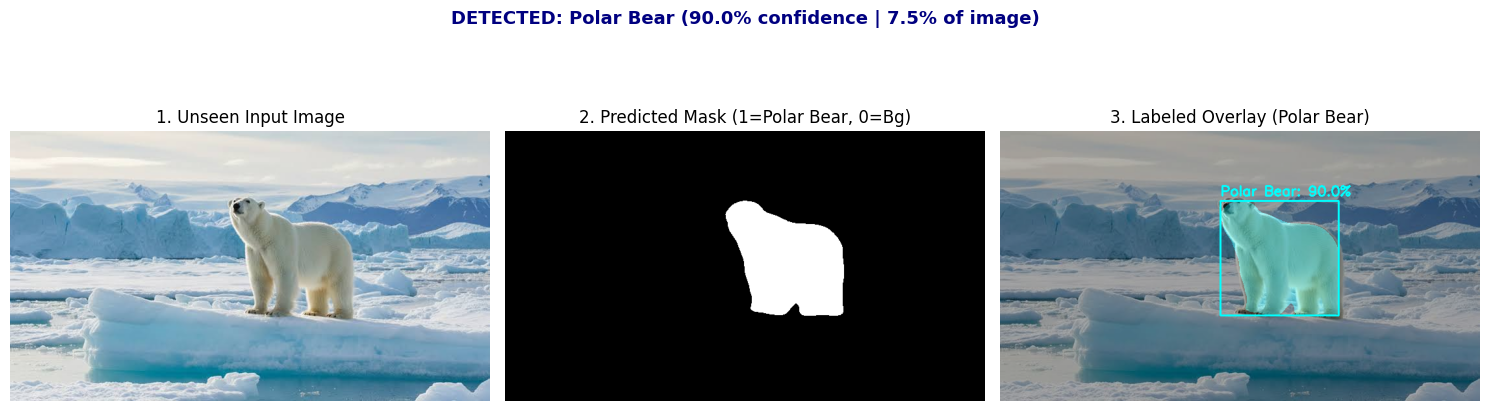

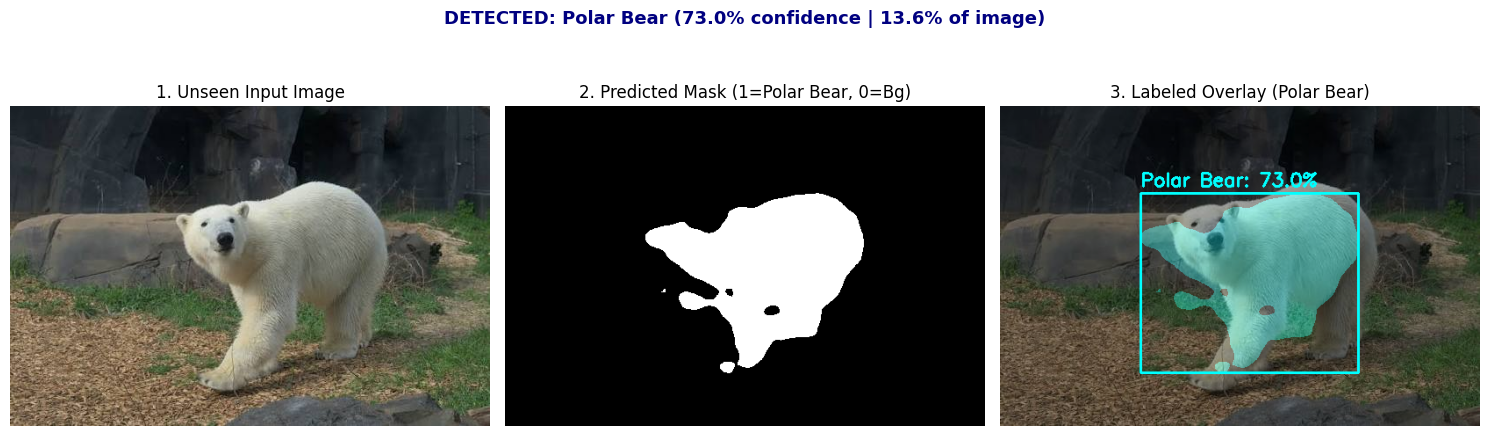

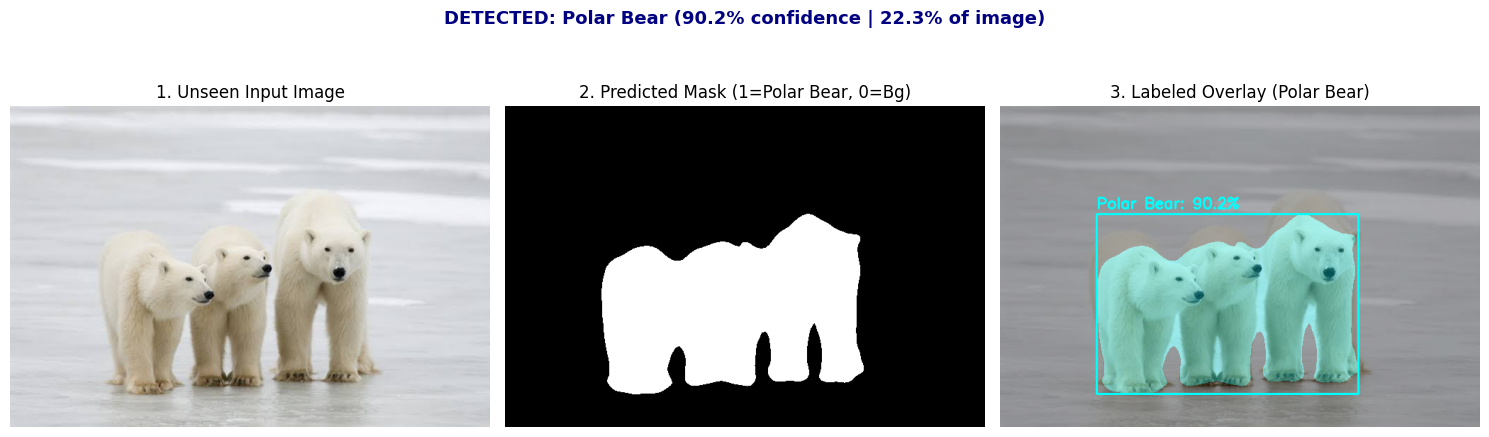

In [20]:
#extra task: to see if this Binary-U-NET model predicts the polr bear with how much accuracy
#keep in mind that the binary UNET doesn't distinguish between different animals
#like predicting if the image animal is a dog or a polar bear since it was only
#trained on polar bears and ot putputa foreground andbackground only: binary..
#however, in below code, we can still say with how much accuracy the thing
#it was traied on was predicted, i.e., polar bears

#For multi-class predictions (to see if it correclty distongushes between a dog a bear)
#we will do multi-class semantic segmentation in tutorial 11. even further,
#we can distinguih between one single class (interclss variations) with
#instance segmentation



#FINAL INFERENCE /PREDICTION CELL WITH CLASS LABEL & CONFIDENCE

import glob, os, cv2
import numpy as np
import matplotlib.pyplot as plt
import torch

CLASS_NAME = "Polar Bear"
best_model = lr_results[1e-3]["model"]
best_model.eval()

def predict_and_label_image(image_path, model, img_size=128, threshold=0.5):
    orig_bgr = cv2.imread(image_path)
    orig_rgb = cv2.cvtColor(orig_bgr, cv2.COLOR_BGR2RGB)
    h_orig, w_orig, _ = orig_rgb.shape

    resized = cv2.resize(orig_rgb, (img_size, img_size)) / 255.0
    input_tensor = torch.tensor(np.transpose(resized, (2, 0, 1)), dtype=torch.float32).unsqueeze(0).to(device)

    with torch.no_grad():
        prob_map = model(input_tensor)[0, 0].cpu().numpy()

    prob_full = cv2.resize(prob_map, (w_orig, h_orig))
    binary_mask = (prob_full > threshold).astype(np.uint8)

    foreground_pixels = np.sum(binary_mask)
    coverage_pct = (foreground_pixels / (h_orig * w_orig)) * 100.0

    overlay = orig_rgb.copy()
    if foreground_pixels > 50:
        confidence = float(prob_full[binary_mask == 1].mean()) * 100.0
        verdict = f"DETECTED: {CLASS_NAME} ({confidence:.1f}% confidence | {coverage_pct:.1f}% of image)"

        color_mask = np.zeros_like(overlay)
        color_mask[binary_mask == 1] = [0, 255, 255]
        overlay = cv2.addWeighted(overlay, 0.7, color_mask, 0.3, 0)

        ys, xs = np.where(binary_mask == 1)
        x1, y1, x2, y2 = xs.min(), ys.min(), xs.max(), ys.max()
        cv2.rectangle(overlay, (x1, y1), (x2, y2), (0, 255, 255), 2)
        cv2.putText(overlay, f"{CLASS_NAME}: {confidence:.1f}%", (x1, max(20, y1 - 8)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 255), 2)
    else:
        verdict = f"NOT DETECTED: No {CLASS_NAME} found (only Background)"

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    axes[0].imshow(orig_rgb); axes[0].set_title("1. Unseen Input Image"); axes[0].axis("off")
    axes[1].imshow(binary_mask, cmap="gray"); axes[1].set_title(f"2. Predicted Mask (1={CLASS_NAME}, 0=Bg)"); axes[1].axis("off")
    axes[2].imshow(overlay); axes[2].set_title(f"3. Labeled Overlay ({CLASS_NAME})"); axes[2].axis("off")
    plt.suptitle(verdict, fontsize=13, fontweight="bold", color="navy")
    plt.tight_layout()
    plt.show()

# Automatically locate your polar bear images anywhere in /content/
all_found_imgs = sorted([
    p for p in glob.glob("/content/**/*.*", recursive=True)
    if p.lower().endswith((".jpg", ".jpeg", ".png")) and "/masks/" not in p and "sample_data" not in p
])

print(f"Found {len(all_found_imgs)} images in /content/. Running predictions...")

if len(all_found_imgs) > 0:
    # Pick the last 3 images (usually validation images)
    for path in all_found_imgs[-3:]:
        predict_and_label_image(path, best_model)
else:
    print("No image files found in /content/. Please check the left Files sidebar to make sure your zip is uploaded and extracted.")